In [ ]:
from tensorflow.keras.datasets import cifar10
import os
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import utils
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, Activation
from tensorflow.keras.optimizers import Adam, SGD
from sklearn.preprocessing import LabelBinarizer
import matplotlib.pyplot as plt
from keras.utils import plot_model
import seaborn as sns

In [ ]:
#Loading in cifar10 file and splitting them into training set and test set
(trainX, trainY), (testX, testY) = cifar10.load_data()

In [ ]:
print('Numer of Training Samples:')
print(f'Number of X Training samples are : {trainX.shape[0]} ')
print(f'Number of Y Training samples are : {trainY.shape[0]} ')
print('=====================================================')
print('Number of Test Samples: ')
print(f'Number of X Testing samples are : {testX.shape[0]}')
print(f'Number of Y Testing samples are : {testY.shape[0]} ')

Numer of Training Samples:
Number of X Training samples are : 50000 
Number of Y Training samples are : 50000 
Number of Test Samples: 
Number of X Testing samples are : 10000
Number of Y Testing samples are : 10000 


In [ ]:
print(f'The range of values in X training is : {trainX.min()}-{trainX.max()} ')
print(f'The range of values in Y training is : {trainY.min()}-{trainY.max()} ')

The range of values in X training is : 0-255 
The range of values in Y training is : 0-9 


In [ ]:
print(f'Size of Images is : {len(trainX[1])}x{len(trainX[2])}')

Size of Images is : 32x32


In [ ]:
print(f'Number of color channels in Training dataset are : {trainX.shape[3]} ')

print('=====================================================')

print(f'Number of color channels in Test datasets are : {testX.shape[3]}')

Number of color channels in Training dataset are : 3 
Number of color channels in Test datasets are : 3


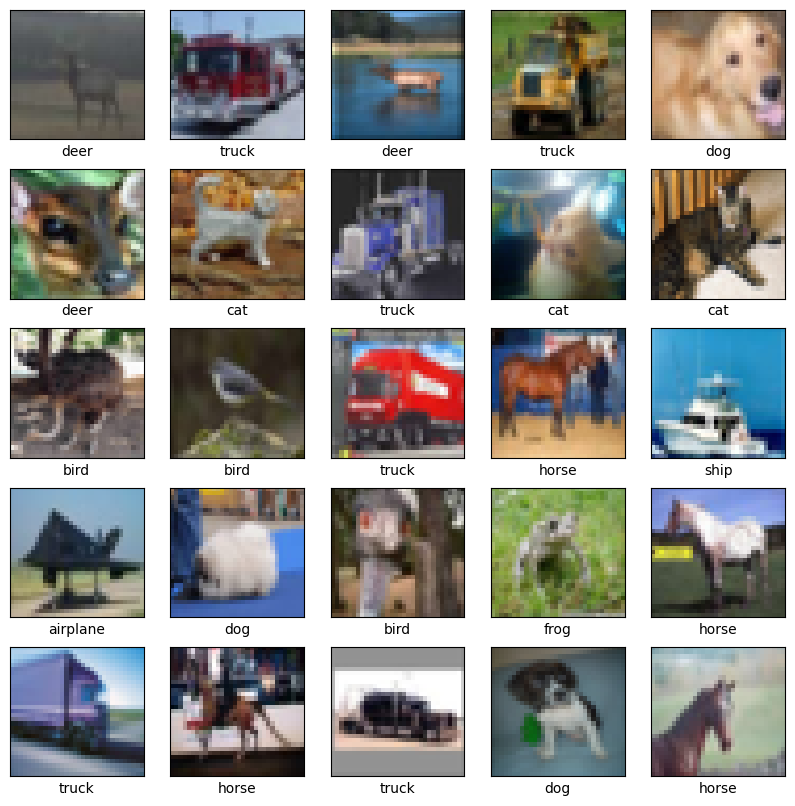

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
n_train = len(trainX)

#Plotting out few images from the dataset
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    index = np.random.randint(0, n_train)
    plt.imshow(trainX[index,1:])
    #The CIFAR labels are in arrays, which is why you need the extra index
    plt.xlabel(class_names[trainY[index][0]])
plt.show()

Text(0.5, 1.0, 'Class distribution in training set')

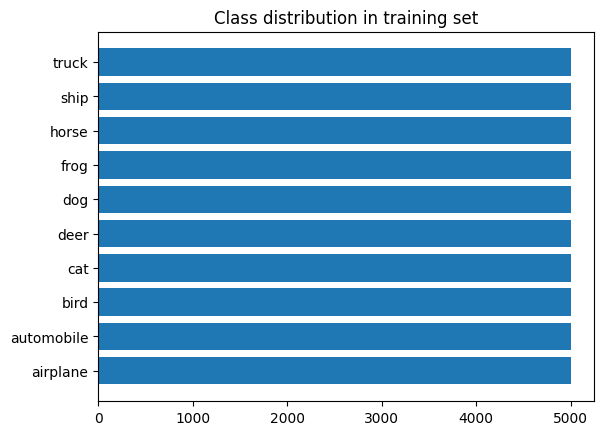

In [ ]:
classes, counts = np.unique(trainY, return_counts=True)
plt.barh(class_names, counts)
plt.title('Class distribution in training set')

Text(0.5, 1.0, 'Class distribution in testing set')

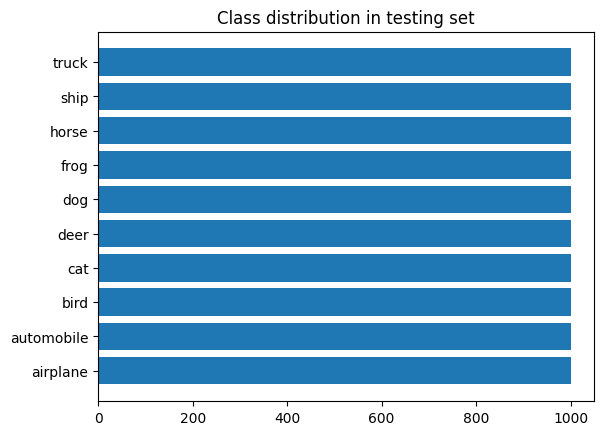

In [ ]:
classes, counts = np.unique(testY, return_counts=True)
plt.barh(class_names, counts)
plt.title('Class distribution in testing set')

In [ ]:
#Convert values to float
trainX = trainX.astype("float")
testX = testX.astype("float")

#Pixel normalisation which divide each instance by 255 so that all the image pixels are between 0 and 1
trainX = trainX / 255.0
testX = testX / 255.0

lb = LabelBinarizer() #The current values in trainY and testY are from 0-9, each corresponding to its respective classes. 
trainY = lb.fit_transform(trainY) #Label binarizer basically one hot encode the array, converting all to 0 except the correct index which will be a 1.
testY = lb.transform(testY)

In [ ]:
def lenet(activation, learning_rate):
  model = keras.models.Sequential([
    #First convolution layer and pooling
    keras.layers.Conv2D(6, kernel_size=5, strides=1,  activation=activation, input_shape=(32,32,3), padding='same'),
    keras.layers.AveragePooling2D(), 

    #Second convolution layer and pooling
    keras.layers.Conv2D(16, kernel_size=5, strides=1, activation=activation, padding='valid'),
    keras.layers.AveragePooling2D(),

    #Third convolution layer
    keras.layers.Conv2D(120, kernel_size=5, strides=1, activation=activation, padding='valid'),

    #Flatten the output from the last convolution layer to build a fully connected layer
    keras.layers.Flatten(),    
    keras.layers.Dense(84, activation=activation),
    keras.layers.Dense(10, activation='softmax')
])
  #Compiling model
  model.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=learning_rate), metrics=['accuracy'])
  
  return model

In [ ]:
model = lenet('relu', 0.001)

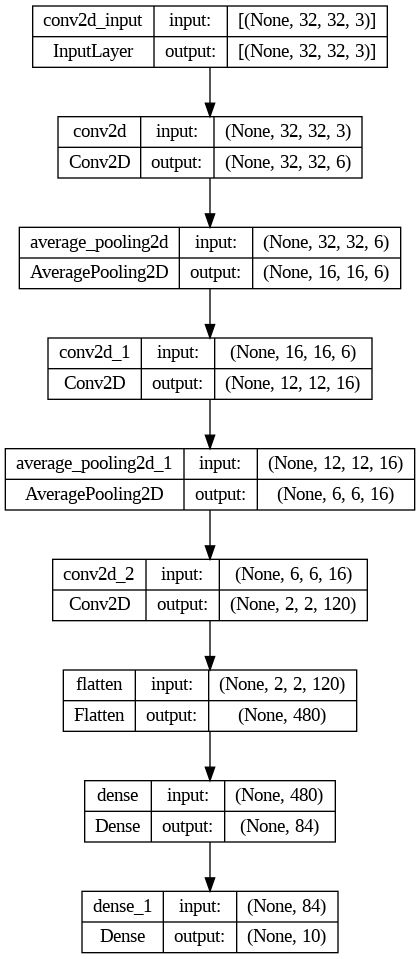

In [ ]:
plot_model(model, to_file = "lenet_cifar10_architecture.png", show_shapes = True)

In [ ]:
Lenet_history = model.fit(trainX, trainY, batch_size=32, steps_per_epoch=n_train // 32, epochs=20, validation_data=(testX, testY),verbose=1)

Epoch 1/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.4837 - accuracy: 0.8332 - val_loss: 2.0786 - val_accuracy: 0.6117
Epoch 2/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.3141 - accuracy: 0.8840 - val_loss: 2.0337 - val_accuracy: 0.6161
Epoch 3/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.3013 - accuracy: 0.8904 - val_loss: 2.1683 - val_accuracy: 0.5870
Epoch 4/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.2822 - accuracy: 0.8977 - val_loss: 2.1496 - val_accuracy: 0.6117
Epoch 5/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.2772 - accuracy: 0.8987 - val_loss: 2.2174 - val_accuracy: 0.6215
Epoch 6/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.2693 - accuracy: 0.9022 - val_loss: 2.1976 - val_accuracy: 0.6182
Epoch 7/20
1562/1562 [==============================] - 8s 5ms/step - loss: 0.2686 - accuracy: 0.9015 - val_loss: 2.2570 - val_accuracy:

In [ ]:
#Print evaluation results
score=model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 1s 4ms/step - loss: 2.9130 - accuracy: 0.6118
Test Score= 2.9130144119262695
Test Accuracy= 0.6118000149726868


In [ ]:
def fit_with(batch_size, activation, learning_rate):
    activationL = ['relu', 'sigmoid', 'tanh']
    activation = activationL[round(activation)]
    model = lenet(activation, learning_rate)
 
    # Train the model with the train dataset. 
    model.fit(trainX, trainY, 
                    batch_size = round(batch_size),
                    steps_per_epoch = round(n_train // batch_size), 
                    epochs = 20, 
                    validation_data= (testX, testY),
                    verbose=0)

    # Evaluate the model with the eval dataset.
    score=model.evaluate(testX, testY)
    print('Test loss:', score[0])
    print('Test accuracy:', score[1])

    # Return the accuracy.
    return score[1]

In [ ]:
from bayes_opt import BayesianOptimization
bounds ={
    'batch_size':(32, 128),
    'activation':(0,2),
    'learning_rate':(0.001, 0.003)
}
optimizer = BayesianOptimization(fit_with, bounds, random_state = 1, verbose = 2)
optimizer.maximize(init_points=6, n_iter=3)

for i, res in enumerate(optimizer.res):
    print("Iteration {}: \n\t{}".format(i, res))

|   iter    |  target   | activa... | batch_... | learni... |
-------------------------------------------------------------
313/313 [==============================] - 1s 3ms/step - loss: 1.3568 - accuracy: 0.5175
Test loss: 1.356844186782837
Test accuracy: 0.5174999833106995
| 1         | 0.5175    | 0.834     | 101.2     | 0.001     |
313/313 [==============================] - 1s 3ms/step - loss: 1.1878 - accuracy: 0.5799
Test loss: 1.1877821683883667
Test accuracy: 0.5799000263214111
| 2         | 0.5799    | 0.6047    | 46.09     | 0.001185  |
313/313 [==============================] - 1s 3ms/step - loss: 1.2176 - accuracy: 0.6279
Test loss: 1.2175562381744385
Test accuracy: 0.6279000043869019
| 3         | 0.6279    | 0.3725    | 65.17     | 0.001794  |
313/313 [==============================] - 1s 3ms/step - loss: 1.2227 - accuracy: 0.5822
Test loss: 1.2227028608322144
Test accuracy: 0.5821999907493591
| 4         | 0.5822    | 1.078     | 72.24     | 0.00237   |
313/313 [========

In [ ]:
print(optimizer.max)

{'target': 0.6442000269889832, 'params': {'activation': 0.40890449946303487, 'batch_size': 116.29927389353077, 'learning_rate': 0.0010547751863958523}}


In [ ]:
activation = 'relu'
batch_size = 128
learning_rate = 0.001

optimized_model = lenet(activation, learning_rate)

Lenet_history = optimized_model.fit(trainX, trainY, 
                                    batch_size=batch_size, 
                                    steps_per_epoch=n_train // batch_size, 
                                    epochs=50, 
                                    validation_data=(testX, testY),
                                    verbose=1)

Epoch 1/50
390/390 [==============================] - 7s 7ms/step - loss: 1.7394 - accuracy: 0.3614 - val_loss: 1.5064 - val_accuracy: 0.4540
Epoch 2/50
390/390 [==============================] - 2s 6ms/step - loss: 1.4547 - accuracy: 0.4747 - val_loss: 1.4097 - val_accuracy: 0.4926
Epoch 3/50
390/390 [==============================] - 2s 5ms/step - loss: 1.3404 - accuracy: 0.5194 - val_loss: 1.2820 - val_accuracy: 0.5392
Epoch 4/50
390/390 [==============================] - 2s 5ms/step - loss: 1.2659 - accuracy: 0.5478 - val_loss: 1.2466 - val_accuracy: 0.5548
Epoch 5/50
390/390 [==============================] - 2s 6ms/step - loss: 1.1986 - accuracy: 0.5747 - val_loss: 1.1825 - val_accuracy: 0.5749
Epoch 6/50
390/390 [==============================] - 2s 6ms/step - loss: 1.1537 - accuracy: 0.5911 - val_loss: 1.1527 - val_accuracy: 0.5903
Epoch 7/50
390/390 [==============================] - 2s 6ms/step - loss: 1.1028 - accuracy: 0.6090 - val_loss: 1.1800 - val_accuracy: 0.5891
Epoch 

In [ ]:
model.save('alexnet.keras')

In [ ]:
score=optimized_model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 1s 3ms/step - loss: 1.6535 - accuracy: 0.6352
Test Score= 1.6535252332687378
Test Accuracy= 0.635200023651123


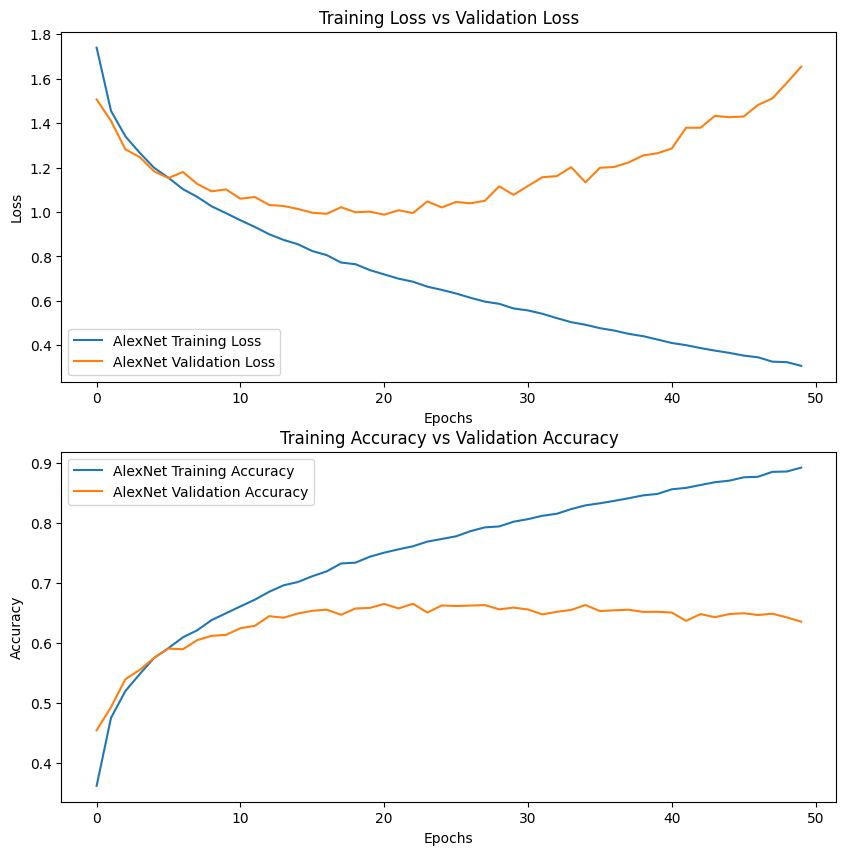

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10,10))

axs[0].plot(Lenet_history.history['loss'])
axs[0].plot(Lenet_history.history['val_loss'])

axs[0].title.set_text('Training Loss vs Validation Loss')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend(['AlexNet Training Loss', 'AlexNet Validation Loss'])

axs[1].plot(Lenet_history.history['accuracy'])
axs[1].plot(Lenet_history.history['val_accuracy'])
axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend(['AlexNet Training Accuracy', 'AlexNet Validation Accuracy'])

In [ ]:
pred = optimized_model.predict(testX)

313/313 [==============================] - 1s 2ms/step


In [ ]:
from sklearn.metrics import classification_report
y_pred = np.argmax(pred, axis=1)
y_true = np.argmax(testY, axis=1)
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.67      0.76      0.71      1000
           1       0.75      0.76      0.76      1000
           2       0.49      0.58      0.53      1000
           3       0.46      0.38      0.42      1000
           4       0.55      0.62      0.58      1000
           5       0.53      0.44      0.48      1000
           6       0.62      0.78      0.69      1000
           7       0.70      0.67      0.69      1000
           8       0.82      0.74      0.78      1000
           9       0.79      0.62      0.70      1000

    accuracy                           0.64     10000
   macro avg       0.64      0.64      0.63     10000
weighted avg       0.64      0.64      0.63     10000



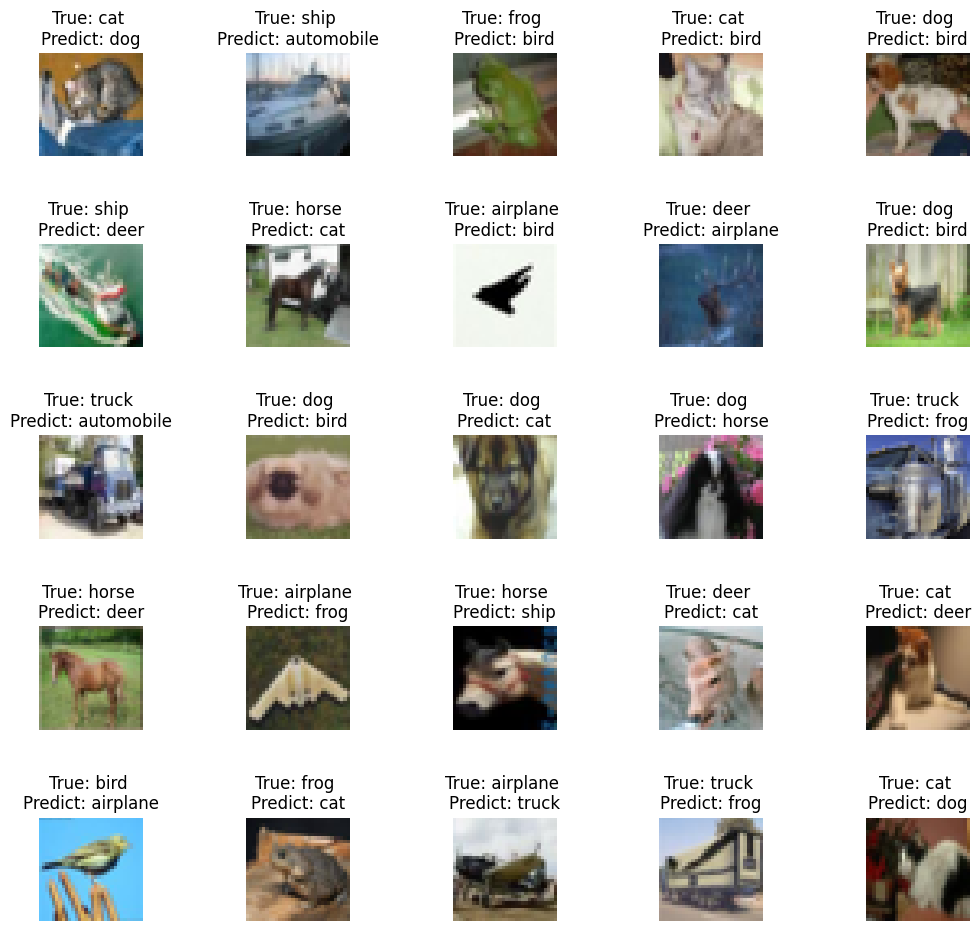

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(12,12))
axes = axes.ravel()

testX = testX * 255

miss_pred = np.where(y_pred != y_true)[0]
for i in np.arange(25): 
    axes[i].imshow(testX[miss_pred[i]].astype('uint8'))
    axes[i].set_title('True: %s \nPredict: %s' % (class_names[y_true[miss_pred[i]]], class_names[y_pred[miss_pred[i]]]))
    axes[i].axis('off')
    plt.subplots_adjust(wspace=1)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
confusion_matrix = tf.math.confusion_matrix(labels=y_true, predictions=y_pred)
confusion_matrix = confusion_matrix.numpy()

Text(0.5, 1.0, 'Confusion Matrix')

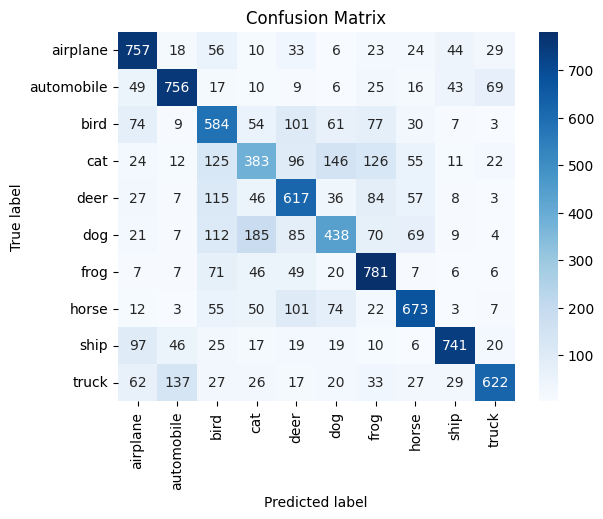

In [ ]:
sns.heatmap(confusion_matrix, annot=True, fmt="g", xticklabels = class_names, yticklabels = class_names, cmap=plt.cm.Blues)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')